In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sc
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [2]:
X, Y_true = make_blobs(n_samples=500,centers=3,cluster_std=4,random_state=42)

In [3]:
df = pd.DataFrame(X,columns=['column1','column2'])

In [4]:
df.head()

,column1,column2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [6]:
wcss = []
k_range = range(1,11)

In [7]:
for k in k_range:
    Kmeans = KMeans(n_clusters=k, random_state=42)
    Kmeans.fit(X_scaled)
    wcss.append(
        Kmeans.inertia_
    )


In [8]:
wcss

[1000.0,
 528.8064432605652,
 294.437706867819,
 250.45524696534466,
 216.88110656982616,
 185.27440675195916,
 156.70879996290458,
 135.62603453115258,
 129.10396348239817,
 119.94101297104999]

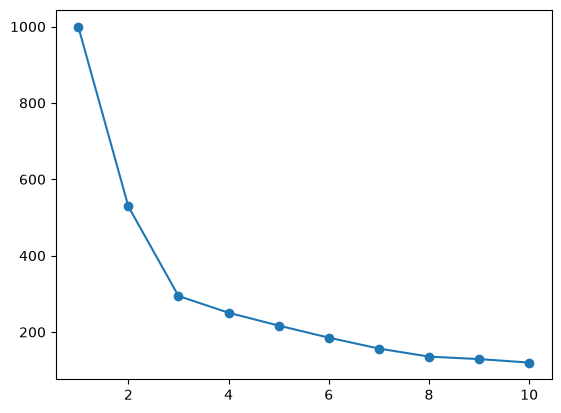

In [9]:
plt.plot(k_range, wcss, marker = 'o')

In [10]:
kmeans_final = KMeans(n_clusters=8, random_state=42)


In [11]:
kp = kmeans_final.fit_predict(X_scaled)

In [12]:
df['cluster'] = kp

<Axes: xlabel='column1', ylabel='column2'>

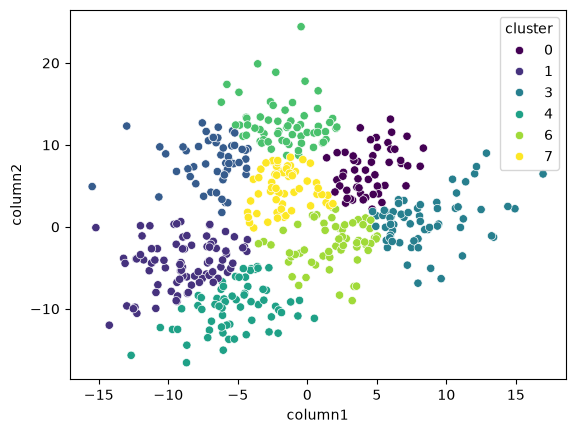

In [13]:
sc.scatterplot(x=df['column1'],
               y=df['column2'],
               hue=df['cluster'],
               palette='viridis')

In [14]:
from sklearn.datasets import make_moons

In [15]:
X, Y_t = make_moons(n_samples=500, noise=0.05, random_state=42)

In [16]:
df2 = pd.DataFrame(X, columns=['First','Sec'])

In [17]:
sca = StandardScaler()
X_sca = sca.fit_transform(df2)

In [18]:
from sklearn.cluster import KMeans, DBSCAN

In [19]:
km  = KMeans(n_clusters=2,random_state=42)
kml = km.fit_predict(X_sca)

In [20]:
df2['km+cluster'] = kml

<Axes: xlabel='First', ylabel='Sec'>

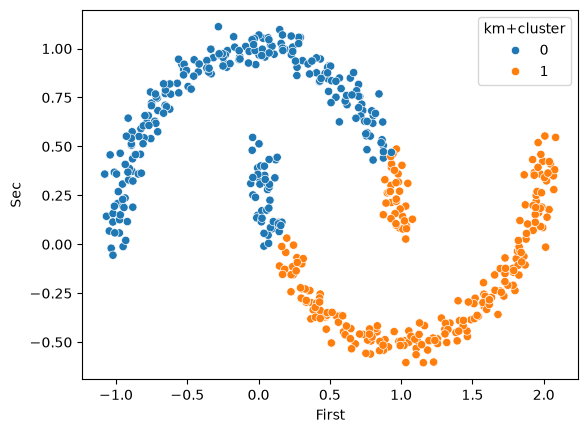

In [21]:
sc.scatterplot(x=df2['First'], y=df2['Sec'],hue=df2['km+cluster'],palette = 'tab10' )

In [22]:
dbscan = DBSCAN(min_samples=5,eps=0.3)
dbl = dbscan.fit_predict(X_sca)

In [23]:
df2['dbscl'] = dbl

<Axes: xlabel='First', ylabel='Sec'>

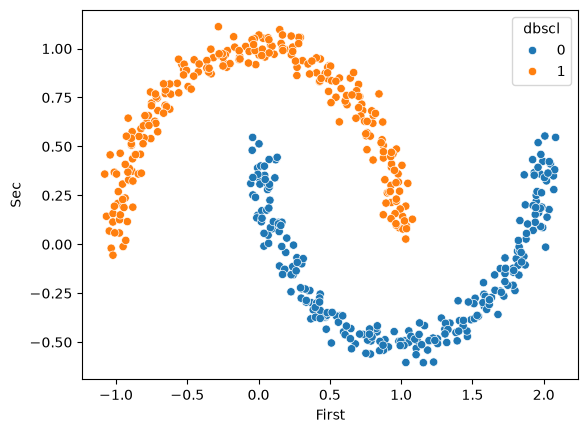

In [24]:
sc.scatterplot(x=df2['First'],y=df2['Sec'],hue=df2['dbscl'],palette='tab10')